In [3]:
from pathlib import Path

import SimpleITK as sitk
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### Configurations and Tools

In [4]:
csv_path = "/Users/furkan/projects/mebar-radiology/preprocessing/configurations/no_alignment/pipeline_checkpoints.csv"
manifest_path = "/Users/furkan/projects/mebar-radiology/data/manifest.csv"
root_path = "/Users/furkan/projects/mebar-radiology"

In [5]:
from IPython.display import display, HTML


# render a dataframe fully (no pandas ellipsis) inside a scrollable container
def show_scrollable(df, max_height="300px"):
    display(HTML(f'<div style="max-height:{max_height}; overflow:auto; border:1px solid #999">{df.to_html()}</div>'))

In [6]:
# buraya
def get_image_path(sample_id):
    row = manifest_df[manifest_df["sample_id"] == sample_id].iloc[0]
    return f"{root_path}/{row["image_path"]}"


# Exploration

In [7]:
manifest_df = pd.read_csv(manifest_path)
csv_df = pd.read_csv(csv_path)

In [8]:
# only ADC samples matter for the negative-voxel fix
project_root = Path(manifest_path).resolve().parent.parent

adc_manifest_df = manifest_df[manifest_df["modality"] == "ADC"].reset_index(drop=True)
adc_manifest_df["image_path"] = adc_manifest_df["image_path"].map(lambda p: str(project_root / p))

adc_csv_df = csv_df[csv_df["modality"] == "ADC"].reset_index(drop=True)

In [9]:
# samples whose max intensity falls below threshold (scale-imbalance indicator)
def low_max_samples(df, path_col="image_out_path", threshold=10.0):
    rows = []
    for sample_id, image_path in zip(df["sample_id"], df[path_col]):
        array = sitk.GetArrayFromImage(sitk.ReadImage(image_path)).astype(np.float64)
        rows.append({"sample_id": sample_id, "file_path": Path(image_path).name, "max": float(array.max())})

    stats_df = pd.DataFrame(rows)
    return stats_df[stats_df["max"] < threshold].reset_index(drop=True)


show_scrollable(low_max_samples(adc_manifest_df, path_col="image_path"))


,sample_id,file_path,max
0,6da62ba89f121b65,CELIK OSMAN.Seq8.Ser602.Img1.nrrd,1.818855
1,003da9c17d67938b,MERDIM BURHAN.Seq16.Ser602.Img1.nrrd,1.818855
2,f2ee2155e8541645,TASIMOVA GULBARSHIN.Seq13.Ser1102.Img1.nrrd,1.818855
3,34457c052fa53b67,TUZ GULSEN.Seq22.Ser1302.Img1.nrrd,3.367249
4,580736da8ab3d87a,ALTINTAS SEVINC.Seq28.Ser2002.Img1.nrrd,2.202749
5,61640251fdc38baa,MASOUD ABDULNABI JUMMAH SALIM.Seq1.Ser502.Img1.nrrd,1.623679
6,9e594f345c74fecc,OZYURT ASIYE.Seq50.Ser2802.Img1.nrrd,3.641424
7,9672ecc7488b9389,RACHEV NIKOLAY.Seq17.Ser1202.Img1.nrrd,1.818855
8,c59b42edffd18083,SIS CEMAL.Seq30.Ser1902.Img1.nrrd,1.818855
9,9d5fc7c15d1bd36e,GOK KADRIYE.Seq55.Ser3002.Img1.nrrd,4.519244


In [10]:
# histogram of voxel intensities for a single image
def plot_intensity_histogram(image_path):
    array = sitk.GetArrayFromImage(sitk.ReadImage(image_path)).astype(np.float64).ravel()
    min_val = array.min()
    max_val = array.max()
    mean_val = array.mean()

    plt.figure(figsize=(10, 4))
    plt.hist(array, bins=100)
    plt.xlabel("intensity")
    plt.ylabel("voxel count")
    plt.title(Path(image_path).name)
    plt.text(
        0.98, 0.95,
        f"min={min_val:.2f}  max={max_val:.2f}  mean={mean_val:.2f}",
        transform=plt.gca().transAxes, ha="right", va="top",
        bbox=dict(facecolor="white", alpha=0.8),
    )
    plt.show()


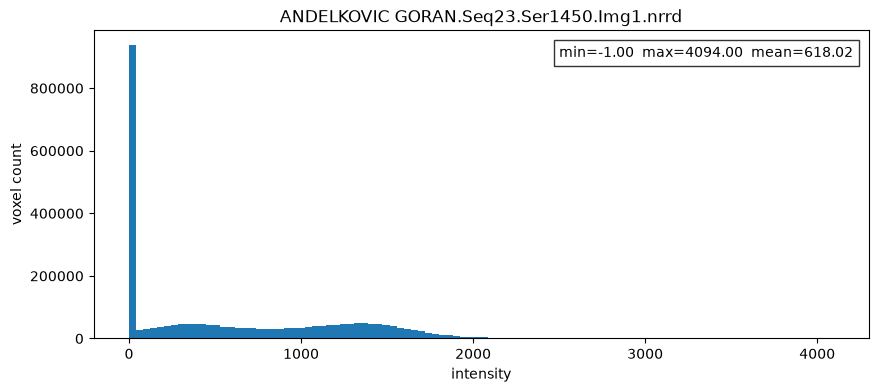

In [11]:
sample_id = "8b579d8c7a2c7cd9"
plot_intensity_histogram(get_image_path(sample_id))

In [12]:
# top-n ADC samples by maximum intensity
def top_max_intensity(n):
    rows = []
    for sample_id, image_path in zip(adc_manifest_df["sample_id"], adc_manifest_df["image_path"]):
        array = sitk.GetArrayFromImage(sitk.ReadImage(image_path)).astype(np.float64)
        rows.append({"sample_id": sample_id, "file_path": Path(image_path).name, "max": float(array.max())})

    return pd.DataFrame(rows).sort_values("max", ascending=False).head(n).reset_index(drop=True)


In [14]:
top_max_intensity(50)

,sample_id,file_path,max
0,d27b47b4999b753a,AKBAS EMINE MELEK.Seq15.Ser800.Img1.nrrd,9042.0
1,3f0c33701d8ba62a,YURTSEVER NEZIHA.Seq18.Ser1102.Img1.nrrd,4095.0
2,280929188ab6e87b,KOC EYUP.Seq25.Ser2002.Img1.nrrd,4095.0
3,a69bccd9e73c2561,3006 Results ADC_b0_800_DWI_5b.nrrd,4095.0
4,3414c9f8620ffaed,GURBAK DURSUN SENEL.Seq15.Ser14.Img1.nrrd,4095.0
5,b9eaf294fa614b40,ESKIKALE SUHEYLA.Seq23.Ser21.Img1.nrrd,4095.0
6,64923d110b368b62,ALEV ALI.Seq13.Ser13.Img1.nrrd,4095.0
7,fb18b31195ce41eb,ABOURADI ABDALMAOTE.Seq37.Ser36.Img1.nrrd,4095.0
8,2ad741a2f8fe3c14,YAVUZER HAYRETTIN.Seq43.Ser92.Img1.nrrd,4095.0
9,6e66c48e0aeeff05,UNUSDU MIRZE.Seq4.Ser302.Img1.nrrd,4095.0


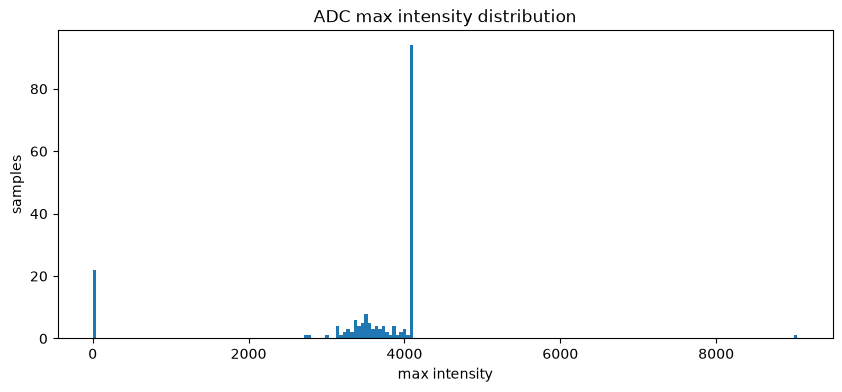

In [16]:
# histogram of per-sample max intensities (ADC)
max_values = []
for image_path in adc_manifest_df["image_path"]:
    array = sitk.GetArrayFromImage(sitk.ReadImage(image_path)).astype(np.float64)
    max_values.append(float(array.max()))

plt.figure(figsize=(10, 4))
plt.hist(max_values, bins=200)
plt.xlabel("max intensity")
plt.ylabel("samples")
plt.title("ADC max intensity distribution")
plt.show()
